# Enterprise Autonomous Intelligence System
## Multi-Agent AI Framework for Predictive Analytics, Automated Decision-Making & Business Intelligence

**Dataset:** [IBM Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

**Goal:** Predict customer churn with a Deep Neural Network, explain predictions with SHAP, convert model scores into tiered retention actions via a LangGraph multi-agent system (with autonomous self-correction), and quantify the business case (revenue-at-risk, campaign ROI sensitivity).




---
## 1. Environment & Configuration


In [1]:
#cell 1
!pip install -q "langchain-core>=0.3.0" "langchain-openai>=0.2.0" "langgraph>=0.2.0" shap joblib

In [2]:
#cell 2
import os, sys, gc, json, random, warnings, logging
from pathlib import Path
from typing import TypedDict, Annotated, Literal, List, Dict, Any, Optional
import operator

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, classification_report, confusion_matrix,
    roc_curve, precision_recall_curve, average_precision_score,
    f1_score, precision_score, recall_score,
)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
import shap
import joblib

from langchain_core.prompts import ChatPromptTemplate
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("EAIS")

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 6), "axes.titlesize": 14, "axes.labelsize": 11, "figure.dpi": 100})

print(f"Python {sys.version.split()[0]} | Pandas {pd.__version__} | NumPy {np.__version__}")
print(f"TensorFlow {tf.__version__} | SHAP {shap.__version__}")
print(f"Seed: {SEED} | CWD: {os.getcwd()}")


Python 3.13.16 | Pandas 2.3.3 | NumPy 2.1.3
TensorFlow 2.21.0 | SHAP 0.54.1
Seed: 42 | CWD: /kaggle/working


In [3]:
import os
os.environ["OPENAI_API_KEY"] = "PUT YOUR OWN KEY"

In [4]:
PROJECT_NAME = "Enterprise Autonomous Intelligence System"
TARGET_COLUMN = "Churn"
VALIDATION_SIZE = 0.20
ID_COLUMN = "customerID"
ARTIFACTS_DIR = Path("artifacts_eais")
ARTIFACTS_DIR.mkdir(exist_ok=True)

LLM_MODEL = "gpt-4o-mini"
LLM_TEMPERATURE = 0.2
RISK_HIGH_THRESHOLD = 0.70
RISK_MEDIUM_THRESHOLD = 0.40

# ---------- LLM setup with multi-provider fallback ----------
LLM_AVAILABLE = False
LLM_PROVIDER = None

# Try 1: OpenAI via Kaggle Secrets
try:
    from kaggle_secrets import UserSecretsClient
    os.environ["OPENAI_API_KEY"] = UserSecretsClient().get_secret("OPENAI_API_KEY")
    LLM_AVAILABLE = True
    LLM_PROVIDER = "openai"
    print(" OpenAI key loaded from Kaggle Secrets")
except Exception:
    if os.environ.get("OPENAI_API_KEY"):
        LLM_AVAILABLE = True
        LLM_PROVIDER = "openai"
        print(" OPENAI_API_KEY loaded from environment")
    else:
        # Try 2: Ollama local fallback
        try:
            import ollama
            ollama.list()
            LLM_AVAILABLE = True
            LLM_PROVIDER = "ollama"
            print(" Ollama detected — using local llama3")
        except Exception:
            print(" No LLM available — MOCK mode (deterministic rules)")

def get_llm():
    if not LLM_AVAILABLE:
        return None
    if LLM_PROVIDER == "openai":
        return ChatOpenAI(model=LLM_MODEL, temperature=LLM_TEMPERATURE)
    return None

def call_llm(prompt: str) -> str:
    """Universal LLM caller with mock fallback."""
    if LLM_PROVIDER == "openai":
        try:
            llm = get_llm()
            return llm.invoke(prompt).content
        except Exception as e:
            logger.warning(f"OpenAI failed: {e}")
    elif LLM_PROVIDER == "ollama":
        try:
            import ollama
            r = ollama.chat(model='llama3', messages=[{'role': 'user', 'content': prompt}])
            return r['message']['content']
        except Exception as e:
            logger.warning(f"Ollama failed: {e}")
    # MOCK fallback — deterministic JSON
    return '{"action_tier": "Medium", "offer": "Email + 10% offer", "estimated_cost": 10.0}'

# ---------- Portable data path ----------
CANDIDATES = [
    Path("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"),
    Path("/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"),
    Path("telco.csv"),
    Path("WA_Fn-UseC_-Telco-Customer-Churn.csv"),
    Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv"),
    Path("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"),
    Path("/home/workdir/artifacts/telco.csv"),
]
DATASET_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATASET_PATH is None:
    raise FileNotFoundError("Telco churn CSV not found. Place telco.csv in working directory.")
print("Dataset path:", DATASET_PATH)

 OPENAI_API_KEY loaded from environment
Dataset path: /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


---
## 2. Data Loading & Schema


In [5]:
#cell 4
train_df = pd.read_csv(DATASET_PATH)
df_original = train_df.copy(deep=True)

if train_df.empty:
    raise ValueError("Dataset is empty.")
if TARGET_COLUMN not in train_df.columns:
    raise KeyError(f"Target column '{TARGET_COLUMN}' not found.")

print(f"Shape: {train_df.shape}")
print(f"Memory: {train_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print("Columns:", train_df.columns.tolist())
display(train_df.head())


Shape: (7043, 21)
Memory: 6.82 MB
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


In [6]:
#cell 5
schema = pd.DataFrame({
    "Column": train_df.columns,
    "Dtype": train_df.dtypes.astype(str).values,
    "Non-Null": train_df.notna().sum().values,
    "Missing": train_df.isna().sum().values,
    "Missing %": (train_df.isna().mean() * 100).round(3).values,
    "Unique": train_df.nunique(dropna=True).values,
})
display(schema)

print("\nTarget distribution:")
target_dist = (
    train_df[TARGET_COLUMN].value_counts(dropna=False)
    .rename_axis("Churn").reset_index(name="Count")
)
target_dist["%"] = (target_dist["Count"] / len(train_df) * 100).round(2)
display(target_dist)
print(f"Duplicates: {train_df.duplicated().sum()}")
if ID_COLUMN in train_df.columns:
    print(f"Duplicate IDs: {train_df[ID_COLUMN].duplicated().sum()}")


,Column,Dtype,Non-Null,Missing,Missing %,Unique
0,customerID,object,7043,0,0.0000,7043
1,gender,object,7043,0,0.0000,2
2,SeniorCitizen,int64,7043,0,0.0000,2
3,Partner,object,7043,0,0.0000,2
4,Dependents,object,7043,0,0.0000,2
5,tenure,int64,7043,0,0.0000,73
6,PhoneService,object,7043,0,0.0000,2
7,MultipleLines,object,7043,0,0.0000,3
8,InternetService,object,7043,0,0.0000,3
9,OnlineSecurity,object,7043,0,0.0000,3



Target distribution:


,Churn,Count,%
0,No,5174,73.4600
1,Yes,1869,26.5400


Duplicates: 0
Duplicate IDs: 0


---
## 3. Data Quality Audit

`TotalCharges` is stored as object and contains blank strings for brand-new customers (tenure = 0). We convert it to numeric and treat blanks as missing, then fill with `tenure × MonthlyCharges`.


In [7]:
#cell 5
hidden = []
for col in train_df.select_dtypes(include="object").columns:
    s = train_df[col].astype("string")
    blank = int(s.str.strip().eq("").sum())
    null_like = int(s.str.strip().str.lower().isin(["na", "n/a", "null", "none", "nan", "?"]).sum())
    if blank or null_like:
        hidden.append({"Feature": col, "Blank": blank, "Null-like": null_like})
if hidden:
    display(pd.DataFrame(hidden))
else:
    print("No blank / null-like strings found.")

train_df["TotalCharges"] = pd.to_numeric(train_df["TotalCharges"], errors="coerce")
print(f"TotalCharges missing after conversion: {train_df['TotalCharges'].isna().sum()}")

mask = train_df["TotalCharges"].isna()
train_df.loc[mask, "TotalCharges"] = (
    train_df.loc[mask, "tenure"] * train_df.loc[mask, "MonthlyCharges"]
)
print(f"TotalCharges missing after fill: {train_df['TotalCharges'].isna().sum()}")
print("SeniorCitizen unique:", sorted(train_df["SeniorCitizen"].unique().tolist()))


,Feature,Blank,Null-like
0,TotalCharges,11,0


TotalCharges missing after conversion: 11
TotalCharges missing after fill: 0
SeniorCitizen unique: [0, 1]


---
## 4. Exploratory Data Analysis


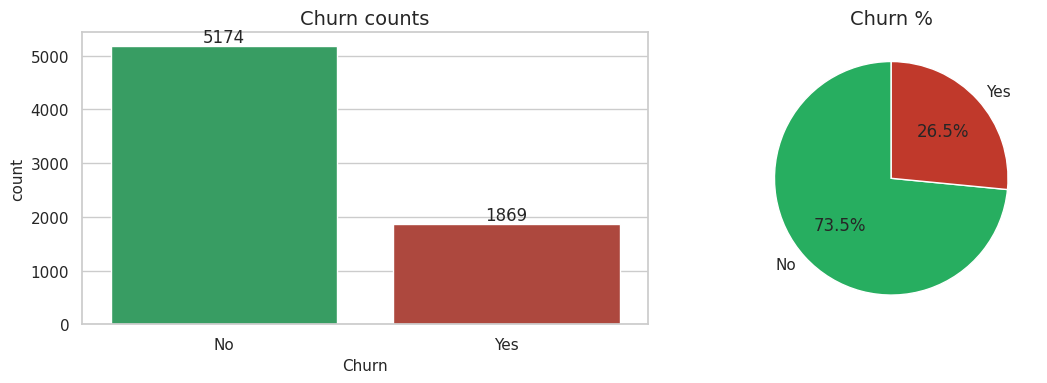

In [8]:
#cell 6
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train_df, x=TARGET_COLUMN, ax=axes[0], order=["No", "Yes"], palette=["#27ae60", "#c0392b"])
for c in axes[0].containers:
    axes[0].bar_label(c)
axes[0].set_title("Churn counts")
counts = train_df[TARGET_COLUMN].value_counts()
axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
            colors=["#27ae60", "#c0392b"])
axes[1].set_title("Churn %")
plt.tight_layout()
plt.show()


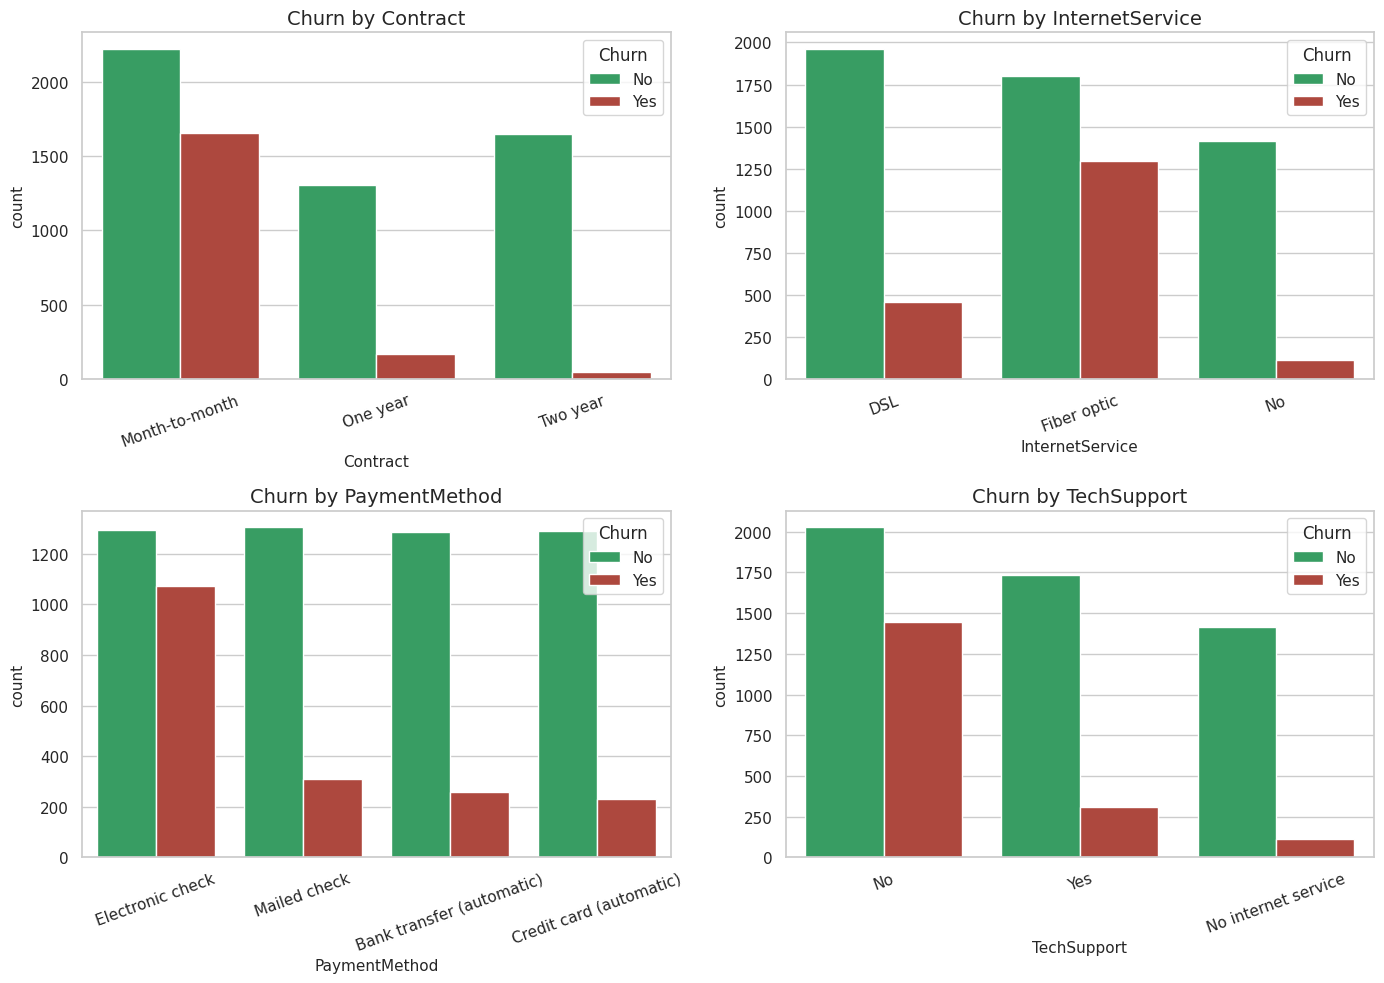

In [9]:
#cell 7
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.ravel(), ["Contract", "InternetService", "PaymentMethod", "TechSupport"]):
    sns.countplot(data=train_df, x=col, hue=TARGET_COLUMN, ax=ax, palette=["#27ae60", "#c0392b"])
    ax.set_title(f"Churn by {col}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


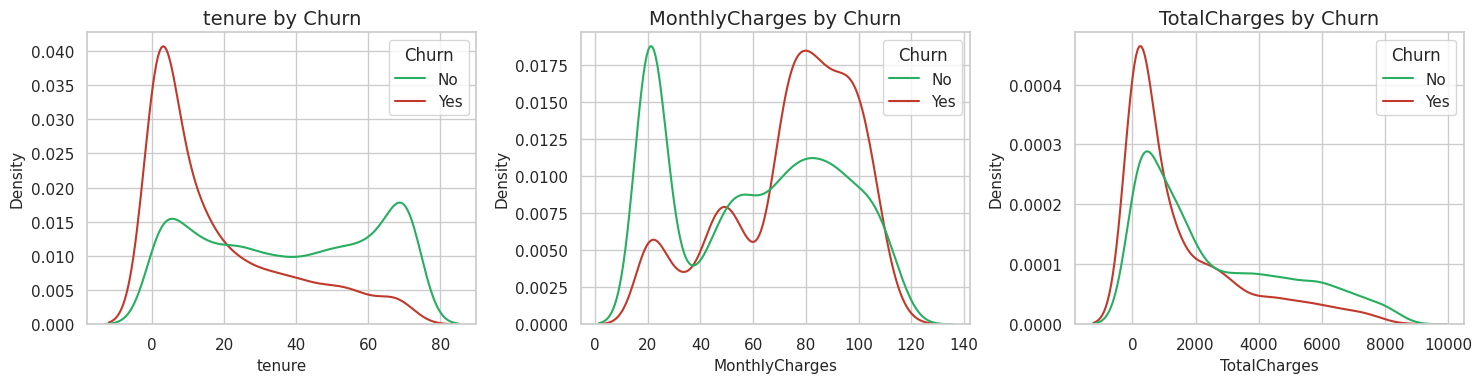

In [10]:
#cell 8
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.kdeplot(data=train_df, x=col, hue=TARGET_COLUMN, ax=ax, common_norm=False,
                palette=["#27ae60", "#c0392b"])
    ax.set_title(f"{col} by Churn")
plt.tight_layout()
plt.show()


---
## 5. Feature Engineering & Train / Validation Split


In [11]:
#cell 9
fe_df = train_df.copy()

fe_df["AvgMonthlySpend"] = fe_df["TotalCharges"] / (fe_df["tenure"].replace(0, np.nan))
fe_df["AvgMonthlySpend"] = fe_df["AvgMonthlySpend"].fillna(fe_df["MonthlyCharges"])
fe_df["IsNewCustomer"] = (fe_df["tenure"] <= 6).astype(int)
fe_df["HasInternet"] = (fe_df["InternetService"] != "No").astype(int)
fe_df["NumAdditionalServices"] = (
    (fe_df["OnlineSecurity"] == "Yes").astype(int)
    + (fe_df["OnlineBackup"] == "Yes").astype(int)
    + (fe_df["DeviceProtection"] == "Yes").astype(int)
    + (fe_df["TechSupport"] == "Yes").astype(int)
    + (fe_df["StreamingTV"] == "Yes").astype(int)
    + (fe_df["StreamingMovies"] == "Yes").astype(int)
)
fe_df["IsMonthToMonth"] = (fe_df["Contract"] == "Month-to-month").astype(int)
fe_df["IsElectronicCheck"] = (fe_df["PaymentMethod"] == "Electronic check").astype(int)
fe_df["ChurnFlag"] = (fe_df[TARGET_COLUMN] == "Yes").astype(int)

print("Feature-engineered shape:", fe_df.shape)
display(fe_df[["tenure", "MonthlyCharges", "TotalCharges", "AvgMonthlySpend",
               "IsNewCustomer", "NumAdditionalServices", "ChurnFlag"]].head())


Feature-engineered shape: (7043, 28)


,tenure,MonthlyCharges,TotalCharges,AvgMonthlySpend,IsNewCustomer,NumAdditionalServices,ChurnFlag
0,1,29.8500,29.8500,29.8500,1,1,0
1,34,56.9500,"1,889.5000",55.5735,0,2,0
2,2,53.8500,108.1500,54.0750,1,2,1
3,45,42.3000,"1,840.7500",40.9056,0,3,0
4,2,70.7000,151.6500,75.8250,1,0,1


In [12]:
#cell 10
id_col = ID_COLUMN
if id_col in fe_df.columns:
    customer_ids = fe_df[id_col].copy()
else:
    customer_ids = pd.Series(range(len(fe_df)), name="customerID")

cat_cols = [c for c in fe_df.select_dtypes(include=["object"]).columns
            if c not in [TARGET_COLUMN, id_col]]
num_cols = [c for c in fe_df.select_dtypes(include=[np.number]).columns if c not in ["ChurnFlag"]]

print("Categorical:", cat_cols)
print("Numerical:", num_cols)

X_cat = pd.get_dummies(fe_df[cat_cols], drop_first=True)
X_num = fe_df[num_cols].copy()
X_all_df = pd.concat([X_num, X_cat], axis=1).astype(np.float32)
y = fe_df["ChurnFlag"].values
feature_names = X_all_df.columns.tolist()
print(f"Final feature matrix: {X_all_df.shape}")


Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlySpend', 'IsNewCustomer', 'HasInternet', 'NumAdditionalServices', 'IsMonthToMonth', 'IsElectronicCheck']
Final feature matrix: (7043, 36)


In [13]:
#cell 11
X_train, X_valid, y_train, y_valid, idx_train, idx_valid = train_test_split(
    X_all_df.values, y, X_all_df.index,
    test_size=VALIDATION_SIZE, random_state=SEED, stratify=y,
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train).astype(np.float32)
X_valid_s = scaler.transform(X_valid).astype(np.float32)

print(f"Train: {X_train_s.shape} | Valid: {X_valid_s.shape}")
print(f"Train churn rate: {y_train.mean():.3f} | Valid: {y_valid.mean():.3f}")


Train: (5634, 36) | Valid: (1409, 36)
Train churn rate: 0.265 | Valid: 0.265


---
## 6. Deep Learning Model (ANN)

Class-weighted binary classifier with BatchNorm, Dropout, EarlyStopping on `val_auc`, and ReduceLROnPlateau.


In [14]:
#cell 12
def build_dnn(input_dim: int, name: str = "churn_dnn") -> keras.Model:
    inp = keras.Input(shape=(input_dim,), name="features")
    x = layers.Dense(128, activation="relu")(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.25)(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.20)(x)
    out = layers.Dense(1, activation="sigmoid", name="churn_prob")(x)
    model = keras.Model(inp, out, name=name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
        ],
    )
    return model

model = build_dnn(X_train_s.shape[1])
model.summary()


Model: "churn_dnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 36)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         4,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ churn_prob (Dense)              │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,873 (62.00 KB)

 Trainable params: 15,489 (60.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [15]:
#cell 13
neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
class_weight = {0: 1.0, 1: neg / pos}
print(f"Class weights: {class_weight}")

es = callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=12, restore_best_weights=True)
rlrop = callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5, patience=5, min_lr=1e-6)
ckpt_path = ARTIFACTS_DIR / "best_churn_dnn.keras"
ckpt = callbacks.ModelCheckpoint(str(ckpt_path), monitor="val_auc", mode="max", save_best_only=True)

history = model.fit(
    X_train_s, y_train,
    validation_data=(X_valid_s, y_valid),
    epochs=80,
    batch_size=64,
    class_weight=class_weight,
    callbacks=[es, rlrop, ckpt],
    verbose=1,
)
print(f"Best checkpoint saved → {ckpt_path}")


Class weights: {0: 1.0, 1: 2.768561872909699}
Epoch 1/80
89/89 ━━━━━━━━━━━━━━━━━━━━ 12s 64ms/step - auc: 0.7665 - loss: 0.8971 - precision: 0.4286 - recall: 0.7692 - val_auc: 0.8263 - val_loss: 0.4920 - val_precision: 0.5381 - val_recall: 0.6979 - learning_rate: 0.0010
Epoch 2/80
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - auc: 0.8138 - loss: 0.7825 - precision: 0.4881 - recall: 0.7940 - val_auc: 0.8318 - val_loss: 0.4827 - val_precision: 0.5152 - val_recall: 0.7701 - learning_rate: 0.0010
Epoch 3/80
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - auc: 0.8182 - loss: 0.7661 - precision: 0.4862 - recall: 0.8007 - val_auc: 0.8371 - val_loss: 0.4794 - val_precision: 0.5161 - val_recall: 0.7727 - learning_rate: 0.0010
Epoch 4/80
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - auc: 0.8247 - loss: 0.7594 - precision: 0.4873 - recall: 0.7967 - val_auc: 0.8400 - val_loss: 0.4793 - val_precision: 0.5246 - val_recall: 0.7701 - learning_rate: 0.0010
Epoch 5/80
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - auc: 0.8271 

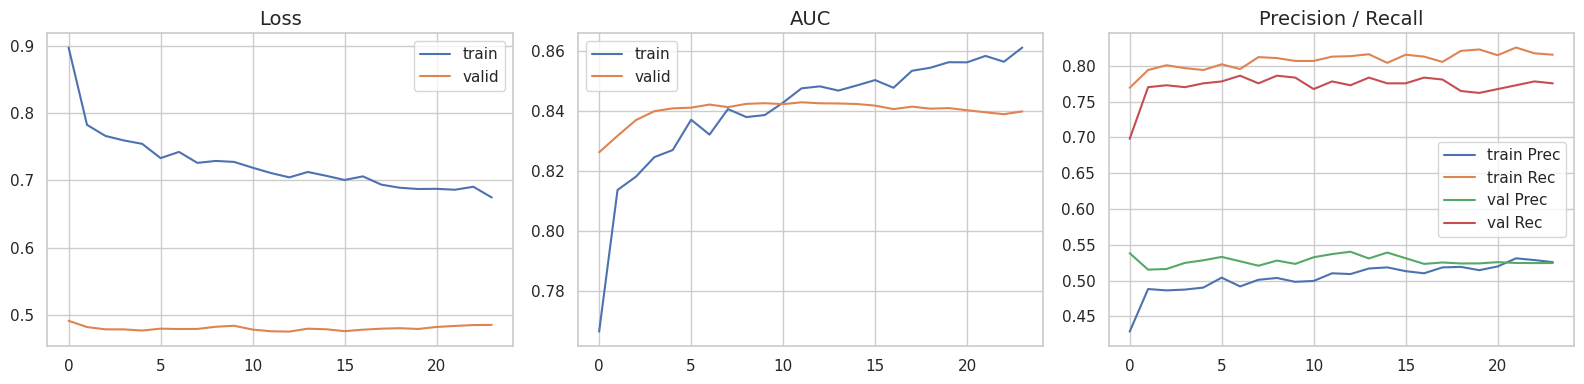

In [16]:
#cell 14
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="valid")
axes[0].set_title("Loss"); axes[0].legend()

axes[1].plot(history.history["auc"], label="train")
axes[1].plot(history.history["val_auc"], label="valid")
axes[1].set_title("AUC"); axes[1].legend()

axes[2].plot(history.history["precision"], label="train Prec")
axes[2].plot(history.history["recall"], label="train Rec")
axes[2].plot(history.history["val_precision"], label="val Prec")
axes[2].plot(history.history["val_recall"], label="val Rec")
axes[2].set_title("Precision / Recall"); axes[2].legend()
plt.tight_layout()
plt.show()


---
## 7. Model Evaluation

ROC-AUC, PR-AUC, classification report, confusion matrix, **optimal threshold** (Youden / max F1), ROC + Precision-Recall curves.


Optimal F1 threshold: 0.5658 (F1=0.6388)

Classification Report (optimal threshold):
              precision    recall  f1-score   support

    No Churn       0.89      0.81      0.85      1035
       Churn       0.58      0.71      0.64       374

    accuracy                           0.79      1409
   macro avg       0.73      0.76      0.74      1409
weighted avg       0.80      0.79      0.79      1409

ROC-AUC : 0.8430
PR-AUC  : 0.6409


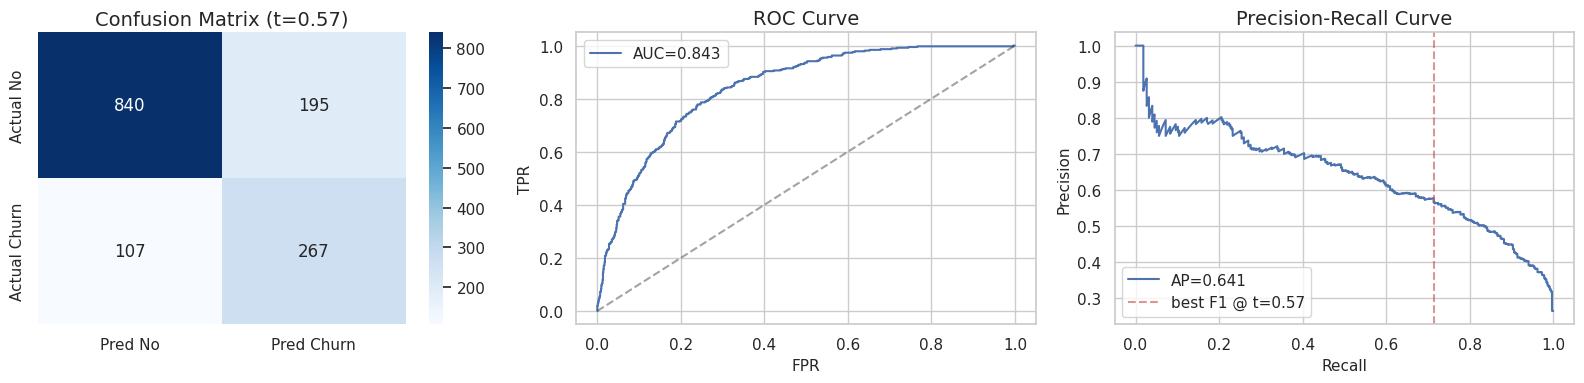

In [17]:
#cell 15
y_prob = model.predict(X_valid_s, verbose=0).ravel()

# Optimal threshold: maximise F1
precisions, recalls, thresholds = precision_recall_curve(y_valid, y_prob)
f1s = 2 * precisions * recalls / (precisions + recalls + 1e-12)
best_f1_idx = np.nanargmax(f1s)
BEST_THRESHOLD = float(thresholds[best_f1_idx]) if best_f1_idx < len(thresholds) else 0.5
print(f"Optimal F1 threshold: {BEST_THRESHOLD:.4f} (F1={f1s[best_f1_idx]:.4f})")

y_pred = (y_prob >= BEST_THRESHOLD).astype(int)

print("\nClassification Report (optimal threshold):")
print(classification_report(y_valid, y_pred, target_names=["No Churn", "Churn"]))
print(f"ROC-AUC : {roc_auc_score(y_valid, y_prob):.4f}")
print(f"PR-AUC  : {average_precision_score(y_valid, y_prob):.4f}")

cm = confusion_matrix(y_valid, y_pred)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Pred No", "Pred Churn"], yticklabels=["Actual No", "Actual Churn"])
axes[0].set_title(f"Confusion Matrix (t={BEST_THRESHOLD:.2f})")

fpr, tpr, _ = roc_curve(y_valid, y_prob)
axes[1].plot(fpr, tpr, label=f"AUC={roc_auc_score(y_valid, y_prob):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR"); axes[1].set_title("ROC Curve")
axes[1].legend()

axes[2].plot(recalls, precisions, label=f"AP={average_precision_score(y_valid, y_prob):.3f}")
axes[2].axvline(recalls[best_f1_idx], color="r", ls="--", alpha=0.6, label=f"best F1 @ t={BEST_THRESHOLD:.2f}")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].set_title("Precision-Recall Curve")
axes[2].legend()
plt.tight_layout()
plt.show()


---
## 8. Model Explainability (SHAP)

DeepExplainer on a background sample. We produce:
1. Global summary (bar + beeswarm-style)
2. Per-customer top-k drivers
3. Force-style contribution bars for top-risk customers


In [18]:
#cell 16
bg_size = 200
np.random.seed(SEED)
bg_idx = np.random.choice(len(X_train_s), size=min(bg_size, len(X_train_s)), replace=False)
background = X_train_s[bg_idx]

# DeepExplainer can be memory-heavy; fall back to KernelExplainer on a small set if needed
try:
    explainer = shap.DeepExplainer(model, background)
    SHAP_MODE = "DeepExplainer"
except Exception as e:
    print("DeepExplainer failed, falling back to KernelExplainer:", e)
    # Use a tiny background for KernelExplainer speed
    bg_small = background[:50]
    def predict_fn(x):
        return model.predict(x, verbose=0).ravel()
    explainer = shap.KernelExplainer(predict_fn, bg_small)
    SHAP_MODE = "KernelExplainer"

print(f"{SHAP_MODE} ready. Background size: {background.shape[0]}")


2026-11-22 10:42:18,995 | WARNING | Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


DeepExplainer ready. Background size: 200


Computing SHAP values for 150 validation samples...


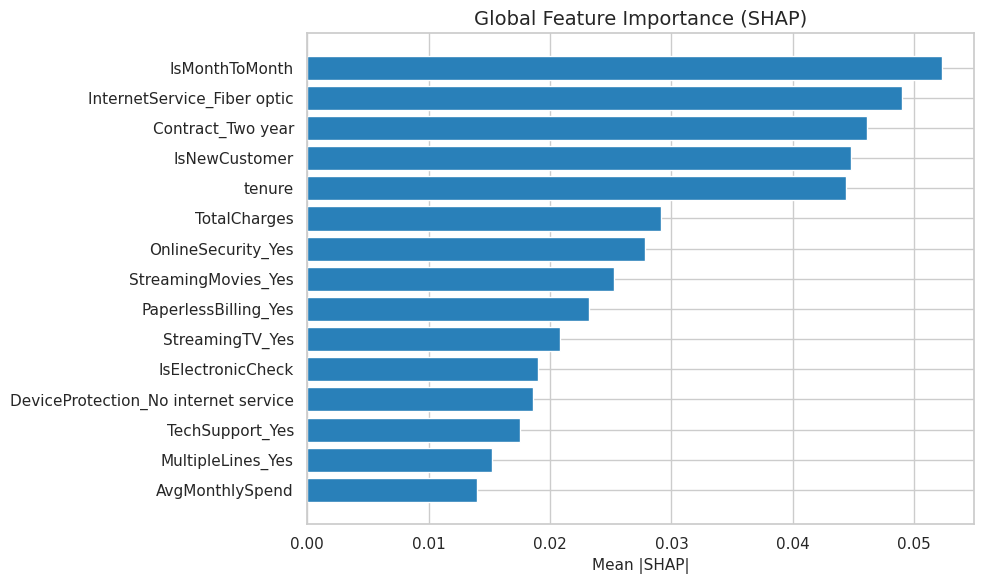

Top SHAP drivers for first validation customer:
  Contract_Two year                    SHAP=-0.1198
  TotalCharges                         SHAP=-0.0739
  IsMonthToMonth                       SHAP=-0.0690
  tenure                               SHAP=-0.0479
  OnlineSecurity_Yes                   SHAP=-0.0416


In [19]:
#cell 18
def explain_customer(x_row: np.ndarray, top_k: int = 5) -> List[Dict[str, Any]]:
    """Return top-k SHAP drivers for a single scaled feature vector."""
    x = np.asarray(x_row, dtype=np.float32).reshape(1, -1)
    sv = explainer.shap_values(x)
    if isinstance(sv, list):
        sv = sv[0]
    sv = np.asarray(sv).reshape(-1)
    order = np.argsort(np.abs(sv))[::-1][:top_k]
    return [{"feature": feature_names[i], "shap": float(sv[i])} for i in order]


def get_shap_vector(x_row: np.ndarray) -> np.ndarray:
    x = np.asarray(x_row, dtype=np.float32).reshape(1, -1)
    sv = explainer.shap_values(x)
    if isinstance(sv, list):
        sv = sv[0]
    return np.asarray(sv).reshape(-1)


# Global SHAP on a validation sample
sample_n = min(150, len(X_valid_s))
np.random.seed(SEED)
sample_idx = np.random.choice(len(X_valid_s), size=sample_n, replace=False)
X_sample = X_valid_s[sample_idx]

print(f"Computing SHAP values for {sample_n} validation samples...")
shap_values = explainer.shap_values(X_sample)
if isinstance(shap_values, list):
    shap_values = shap_values[0]
shap_values = np.asarray(shap_values)
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 0]

mean_abs = np.abs(shap_values).mean(axis=0)
top_global = np.argsort(mean_abs)[::-1][:15]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh([feature_names[i] for i in top_global[::-1]], mean_abs[top_global][::-1], color="#2980b9")
ax.set_xlabel("Mean |SHAP|")
ax.set_title("Global Feature Importance (SHAP)")
plt.tight_layout()
plt.show()

# Demo on first validation customer
demo_shap = explain_customer(X_valid_s[0], top_k=5)
print("Top SHAP drivers for first validation customer:")
for d in demo_shap:
    print(f"  {d['feature']:35s}  SHAP={d['shap']:+.4f}")


---
## 9. Score Full Population & Risk Tiers


In [20]:
#cell 19
X_all = scaler.transform(X_all_df.values).astype(np.float32)
all_probs = model.predict(X_all, verbose=0).ravel()

scored = fe_df.copy()
scored["ChurnProb"] = all_probs
# Annual revenue-at-risk = MonthlyCharges × 12 × churn_prob
scored["RevenueAtRisk"] = scored["MonthlyCharges"] * 12 * scored["ChurnProb"]
# CLV proxy
scored["CLV"] = scored["MonthlyCharges"] * scored["tenure"].clip(lower=1)

def risk_tier(p):
    if p >= RISK_HIGH_THRESHOLD:
        return "High"
    if p >= RISK_MEDIUM_THRESHOLD:
        return "Medium"
    return "Low"

scored["RiskTier"] = scored["ChurnProb"].apply(risk_tier)

print("Risk tier distribution:")
display(scored["RiskTier"].value_counts().rename("Count").to_frame())

print(f"\nTotal annual revenue at risk: ${scored['RevenueAtRisk'].sum():,.2f}")
print(f"High-risk customers: {(scored['RiskTier']=='High').sum()}")

top_risk = scored.nlargest(10, "ChurnProb")
print("\nTop 10 highest churn-probability customers:")
display(top_risk[[id_col, "tenure", "MonthlyCharges", "Contract", "ChurnProb", "RiskTier", "RevenueAtRisk"]].round(3))


Risk tier distribution:


,Count
RiskTier,
Low,3547
Medium,2017
High,1479



Total annual revenue at risk: $2,415,102.06
High-risk customers: 1479

Top 10 highest churn-probability customers:


,customerID,tenure,MonthlyCharges,Contract,ChurnProb,RiskTier,RevenueAtRisk
6482,5419-JPRRN,1,101.4500,Month-to-month,0.9630,High,"1,172.8870"
2797,6023-YEBUP,3,100.9500,Month-to-month,0.9610,High,"1,164.7320"
5933,6496-SLWHQ,3,105.0000,Month-to-month,0.9590,High,"1,208.9410"
6232,9681-OXGVC,5,100.5000,Month-to-month,0.9570,High,"1,154.1020"
6866,0295-PPHDO,1,95.4500,Month-to-month,0.9560,High,"1,094.6330"
2577,4910-GMJOT,1,94.6000,Month-to-month,0.9540,High,"1,082.4930"
3209,8149-RSOUN,1,93.8500,Month-to-month,0.9530,High,"1,073.6150"
3871,5299-SJCZT,3,101.5500,Month-to-month,0.9530,High,"1,161.6860"
969,3158-MOERK,2,96.0000,Month-to-month,0.9530,High,"1,097.8700"
4800,9300-AGZNL,1,94.0000,Month-to-month,0.9530,High,"1,074.8340"


---
## 10. Multi-Agent Decision Framework (LangGraph)



In [21]:
#cell 20
class AgentState(TypedDict):
    customer_id: str
    customer_features: Dict[str, Any]
    churn_prob: float
    risk_tier: str
    shap_explanation: List[Dict[str, Any]]
    revenue_at_risk: float
    retention_actions: List[str]
    offer_cost: float
    expected_savings: float
    roi: float
    business_summary: str
    final_report: str
    retry_count: int
    log: Annotated[List[str], operator.add]


# Pick one high-risk customer for individual agent demos
demo_row = top_risk.iloc[0]
demo_idx = scored.index.get_loc(demo_row.name)
demo_x = X_all[demo_idx]

demo_state: AgentState = {
    "customer_id": str(demo_row[id_col]),
    "customer_features": {
        "tenure": float(demo_row["tenure"]),
        "MonthlyCharges": float(demo_row["MonthlyCharges"]),
        "TotalCharges": float(demo_row["TotalCharges"]),
        "Contract": str(demo_row["Contract"]),
        "InternetService": str(demo_row["InternetService"]),
        "PaymentMethod": str(demo_row["PaymentMethod"]),
    },
    "churn_prob": float(demo_row["ChurnProb"]),
    "risk_tier": "",
    "shap_explanation": explain_customer(demo_x, top_k=5),
    "revenue_at_risk": float(demo_row["RevenueAtRisk"]),
    "retention_actions": [],
    "offer_cost": 0.0,
    "expected_savings": 0.0,
    "roi": 0.0,
    "business_summary": "",
    "final_report": "",
    "retry_count": 0,
    "log": [],
}

print("Demo customer prepared:")
print(f"  ID              : {demo_state['customer_id']}")
print(f"  Churn Prob      : {demo_state['churn_prob']:.4f}")
print(f"  Revenue at Risk : ${demo_state['revenue_at_risk']:.2f}")
print(f"  Features        : {demo_state['customer_features']}")
print(f"  SHAP drivers    : {[d['feature'] for d in demo_state['shap_explanation']]}")
print(f"\nLLM available    : {LLM_AVAILABLE}")


Demo customer prepared:
  ID              : 5419-JPRRN
  Churn Prob      : 0.9634
  Revenue at Risk : $1172.89
  Features        : {'tenure': 1.0, 'MonthlyCharges': 101.45, 'TotalCharges': 101.45, 'Contract': 'Month-to-month', 'InternetService': 'Fiber optic', 'PaymentMethod': 'Electronic check'}
  SHAP drivers    : ['IsNewCustomer', 'InternetService_Fiber optic', 'tenure', 'TotalCharges', 'IsMonthToMonth']

LLM available    : True


### 10.1 Risk Agent
Assigns **High / Medium / Low** tier from churn probability.


In [22]:
#cell 21
def risk_agent(state: AgentState) -> Dict:
    """Risk Agent — pure rule-based tier assignment."""
    p = state["churn_prob"]
    if p >= RISK_HIGH_THRESHOLD:
        tier = "High"
    elif p >= RISK_MEDIUM_THRESHOLD:
        tier = "Medium"
    else:
        tier = "Low"
    msg = f"[RiskAgent] prob={p:.3f} → tier={tier}"
    logger.info(msg)
    return {"risk_tier": tier, "log": [msg]}


print(risk_agent(demo_state))


2026-11-22 10:42:22,431 | INFO | [RiskAgent] prob=0.963 → tier=High


{'risk_tier': 'High', 'log': ['[RiskAgent] prob=0.963 → tier=High']}


### 10.2 Explanation Agent
Surfaces the top SHAP drivers already computed for the customer.


In [23]:
#cell 22
def explanation_agent(state: AgentState) -> Dict:
    """Explanation Agent — formats top SHAP drivers."""
    drivers = state.get("shap_explanation") or []
    lines = [f"{d['feature']} ({d['shap']:+.3f})" for d in drivers]
    msg = f"[ExplainAgent] top drivers: {', '.join(lines)}"
    logger.info(msg)
    return {"log": [msg]}


print(explanation_agent(demo_state))


2026-11-22 10:42:22,449 | INFO | [ExplainAgent] top drivers: IsNewCustomer (+0.072), InternetService_Fiber optic (+0.054), tenure (+0.052), TotalCharges (+0.038), IsMonthToMonth (+0.035)


{'log': ['[ExplainAgent] top drivers: IsNewCustomer (+0.072), InternetService_Fiber optic (+0.054), tenure (+0.052), TotalCharges (+0.038), IsMonthToMonth (+0.035)']}


### 10.3 Retention Agent (LLM-powered)

Recommends 3 concrete retention actions. Uses live LLM when key is set; otherwise deterministic mock rules.
On retry (ROI was negative), switches to a cheaper action set.


In [24]:
#cell 23
def retention_agent(state: AgentState) -> Dict:
    """Retention Agent — LLM (or mock) generates retention actions."""
    is_retry = state.get("retry_count", 0) > 0
    tier = state.get("risk_tier", "Medium")
    feats = state["customer_features"]

    try:
        llm = get_llm()
    except Exception as e:
        logger.warning(f"get_llm() failed: {e}")
        llm = None

    text = None
    mode = None

    if llm is not None:
        try:
            system = (
                "You are a telecom retention specialist. "
                "Return EXACTLY 3 numbered, concrete retention actions. "
                "If retry_mode=true, prefer LOW-COST actions only. "
                "Be concise. Output plain text, no JSON."
            )
            human = (
                "Customer {cid}\nFeatures: {feats}\nChurnProb: {prob:.3f}\nTier: {tier}\n"
                "SHAP drivers: {shap}\nretry_mode: {retry}\n"
                "Revenue at risk (annual): ${rar:.2f}"
            )
            prompt = ChatPromptTemplate.from_messages([("system", system), ("human", human)])
            chain = prompt | llm
            resp = chain.invoke({
                "cid": state["customer_id"],
                "feats": json.dumps(feats),
                "prob": state["churn_prob"],
                "tier": tier,
                "shap": json.dumps(state.get("shap_explanation", [])),
                "retry": is_retry,
                "rar": state.get("revenue_at_risk", 0),
            })
            text = resp.content if hasattr(resp, "content") else str(resp)
            mode = "LLM"
        except Exception as e:
            logger.warning(f"LLM retention_agent failed: {e} — falling back to MOCK")
            text = None

    # ---- MOCK fallback (also used if LLM failed) ----
    if text is None:
        if is_retry:
            actions = [
                "1. Send personalised retention email with 5% loyalty credit (low cost).",
                "2. Offer free TechSupport upgrade for 1 month.",
                "3. Invite to self-service plan review webinar.",
            ]
            mode = "MOCK-RETRY"
        elif tier == "High":
            actions = [
                "1. Outbound retention call + 20% discount for 3 months.",
                "2. Propose 1-year contract conversion with 1 month free.",
                "3. Assign dedicated account manager for 30-day check-in.",
            ]
            if feats.get("Contract") == "Month-to-month":
                actions[1] = "2. Strongly push 1-year contract with 2 months free."
            mode = "MOCK-HIGH"
        elif tier == "Medium":
            actions = [
                "1. Email offer: 10% discount for 2 months.",
                "2. Highlight unused features (Streaming / Security).",
                "3. Nudge to annual plan with small bonus.",
            ]
            mode = "MOCK-MED"
        else:
            actions = [
                "1. Include in monthly newsletter with tips.",
                "2. Soft cross-sell of add-on services.",
                "3. Thank-you message for loyalty.",
            ]
            mode = "MOCK-LOW"
    else:
        actions = [ln.strip() for ln in text.strip().split("\n") if ln.strip()][:3]
        if len(actions) < 3:
            actions = actions + ["(action pending)"] * (3 - len(actions))

    msg = f"[RetentionAgent/{mode}] actions={actions}"
    logger.info(msg)
    return {"retention_actions": actions, "log": [msg]}


print(json.dumps(retention_agent(demo_state), indent=2)[:500])

2026-11-22 10:42:22,467 | INFO | langchain-openai detected system proxy configuration and no explicit `http_socket_options` / `http_client` / `http_async_client` / `openai_proxy`; skipping the custom `httpx` transport so httpx's env-proxy auto-detection applies. Pass `http_socket_options=[...]` to opt back into kernel-level TCP keepalive tuning on top of the env proxy.
2026-11-22 10:42:24,287 | INFO | HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 401 Unauthorized"
2026-11-22 10:42:24,290 | WARNING | LLM retention_agent failed: Error code: 401 - {'error': {'message': 'Incorrect API key provided: gsk_k6hT********************************************Hkpc. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_api_key'}} — falling back to MOCK
2026-11-22 10:42:24,291 | INFO | [RetentionAgent/MOCK-LOW] actions=['1. Include in monthly newsletter with tips.', '2. Soft cross-sell of 

{
  "retention_actions": [
    "1. Include in monthly newsletter with tips.",
    "2. Soft cross-sell of add-on services.",
    "3. Thank-you message for loyalty."
  ],
  "log": [
    "[RetentionAgent/MOCK-LOW] actions=['1. Include in monthly newsletter with tips.', '2. Soft cross-sell of add-on services.', '3. Thank-you message for loyalty.']"
  ]
}


### 10.4 Impact Agent (LLM-powered)

Estimates campaign cost, expected savings, and ROI.  
Uses simple economics when in MOCK mode; LLM when available.


In [25]:
#cell 24
def impact_agent(state: AgentState) -> Dict:
    """Impact Agent — estimates cost, savings, ROI."""
    llm = get_llm()
    tier = state.get("risk_tier", "Medium")
    rar = float(state.get("revenue_at_risk", 0))  # annual
    monthly = float(state["customer_features"].get("MonthlyCharges", 50))
    is_retry = state.get("retry_count", 0) > 0

    # Rule-based economics (always computed; LLM can override narrative)
    cost_map = {"High": 45.0, "Medium": 20.0, "Low": 5.0}
    success_map = {"High": 0.35, "Medium": 0.25, "Low": 0.10}
    offer_cost = cost_map.get(tier, 20.0)
    if is_retry:
        offer_cost *= 0.4  # cheaper re-plan
    success = success_map.get(tier, 0.25)
    expected_savings = rar * success  # annual $ saved
    roi = (expected_savings - offer_cost) / offer_cost if offer_cost > 0 else 0.0

    summary = (
        f"Tier={tier} | cost=${offer_cost:.0f} | success={success:.0%} | "
        f"E[save]=${expected_savings:.0f} | ROI={roi:.1%}"
    )

    if llm is not None:
        try:
            prompt = ChatPromptTemplate.from_messages([
                ("system",
                 "You are a telecom finance analyst. Given the numbers, write 2 short sentences "
                 "on whether the retention campaign is justified. Do not invent new numbers."),
                ("human",
                 "Customer {cid}, tier={tier}, annual revenue-at-risk=${rar:.0f}, "
                 "offer_cost=${cost:.0f}, assumed_success={succ:.0%}, expected_savings=${sav:.0f}, ROI={roi:.1%}. "
                 "Actions: {actions}"),
            ])
            chain = prompt | llm
            resp = chain.invoke({
                "cid": state["customer_id"], "tier": tier, "rar": rar,
                "cost": offer_cost, "succ": success, "sav": expected_savings,
                "roi": roi, "actions": state.get("retention_actions", []),
            })
            narrative = resp.content if hasattr(resp, "content") else str(resp)
            summary = summary + " | " + narrative.strip()[:200]
        except Exception as e:
            logger.warning("Impact LLM failed: %s", e)

    msg = f"[ImpactAgent] {summary}"
    logger.info(msg)
    return {
        "offer_cost": offer_cost,
        "expected_savings": expected_savings,
        "roi": roi,
        "business_summary": summary,
        "log": [msg],
    }


print(json.dumps(impact_agent({**demo_state, "risk_tier": "High", "retention_actions": ["call"]}), indent=2))


2026-11-22 10:42:24,427 | INFO | HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 401 Unauthorized"
2026-11-22 10:42:24,429 | WARNING | Impact LLM failed: Error code: 401 - {'error': {'message': 'Incorrect API key provided: gsk_k6hT********************************************Hkpc. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_api_key'}}
2026-11-22 10:42:24,430 | INFO | [ImpactAgent] Tier=High | cost=$45 | success=35% | E[save]=$411 | ROI=812.2%


{
  "offer_cost": 45.0,
  "expected_savings": 410.5103214508295,
  "roi": 8.122451587796212,
  "business_summary": "Tier=High | cost=$45 | success=35% | E[save]=$411 | ROI=812.2%",
  "log": [
    "[ImpactAgent] Tier=High | cost=$45 | success=35% | E[save]=$411 | ROI=812.2%"
  ]
}


### 10.5 Report Agent
Assembles a structured customer retention brief.


In [26]:
#cell 25
def report_agent(state: AgentState) -> Dict:
    """Report Agent — writes the final structured brief."""
    llm = get_llm()
    actions_txt = "\n".join(state.get("retention_actions") or ["(none)"])
    drivers_txt = ", ".join(
        f"{d['feature']} ({d['shap']:+.3f})" for d in (state.get("shap_explanation") or [])
    )

    report = f"""
══════════════════════════════════════════════════
 CUSTOMER RETENTION BRIEF
══════════════════════════════════════════════════
 Customer ID     : {state['customer_id']}
 Churn Prob      : {state['churn_prob']:.3f}
 Risk Tier       : {state.get('risk_tier', 'n/a')}
 Revenue at Risk : ${state.get('revenue_at_risk', 0):,.2f} / year
 Key Drivers     : {drivers_txt}

 Recommended Actions:
{actions_txt}

 Economics
   Offer cost        : ${state.get('offer_cost', 0):.2f}
   Expected savings  : ${state.get('expected_savings', 0):,.2f}
   ROI               : {state.get('roi', 0):.1%}
   Retry count       : {state.get('retry_count', 0)}

 Summary: {state.get('business_summary', '')}
══════════════════════════════════════════════════
""".strip()

    if llm is not None:
        try:
            prompt = ChatPromptTemplate.from_messages([
                ("system", "You are an executive briefing writer. Tighten the brief below into 5 crisp bullet points. Keep all numbers."),
                ("human", "{report}"),
            ])
            chain = prompt | llm
            resp = chain.invoke({"report": report})
            extra = resp.content if hasattr(resp, "content") else str(resp)
            report = report + "\n\nLLM Executive Bullets:\n" + extra.strip()[:600]
        except Exception as e:
            logger.warning("Report LLM failed: %s", e)

    msg = f"[ReportAgent] brief generated for {state['customer_id']}"
    logger.info(msg)
    return {"final_report": report, "log": [msg]}


out = report_agent({**demo_state, "risk_tier": "High", "retention_actions": ["1. Call"], "offer_cost": 45, "expected_savings": 200, "roi": 3.4, "business_summary": "Strong case"})
print(out["final_report"][:800])


2026-11-22 10:42:24,482 | INFO | HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 401 Unauthorized"
2026-11-22 10:42:24,483 | WARNING | Report LLM failed: Error code: 401 - {'error': {'message': 'Incorrect API key provided: gsk_k6hT********************************************Hkpc. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_api_key'}}
2026-11-22 10:42:24,483 | INFO | [ReportAgent] brief generated for 5419-JPRRN


══════════════════════════════════════════════════
 CUSTOMER RETENTION BRIEF
══════════════════════════════════════════════════
 Customer ID     : 5419-JPRRN
 Churn Prob      : 0.963
 Risk Tier       : High
 Revenue at Risk : $1,172.89 / year
 Key Drivers     : IsNewCustomer (+0.072), InternetService_Fiber optic (+0.054), tenure (+0.052), TotalCharges (+0.038), IsMonthToMonth (+0.035)

 Recommended Actions:
1. Call

 Economics
   Offer cost        : $45.00
   Expected savings  : $200.00
   ROI               : 340.0%
   Retry count       : 0

 Summary: Strong case
══════════════════════════════════════════════════


### 10.6 Orchestrator (LangGraph) with Autonomous Self-Correction

Pipeline: **Risk → Explanation → Retention → Impact → (if ROI < 0 and retry_count == 0 → back to Retention) → Report**


In [27]:
#cell 26
def should_replan(state: AgentState) -> Literal["replan", "report"]:
    """Conditional edge: negative ROI on first pass → replan once."""
    roi = state.get("roi", 0)
    retries = state.get("retry_count", 0)
    if roi < 0 and retries < 1:
        return "replan"
    return "report"


def bump_retry(state: AgentState) -> Dict:
    """Increment retry counter before looping back to Retention."""
    rc = state.get("retry_count", 0) + 1
    msg = f"[Orchestrator] ROI negative → replan (retry={rc})"
    logger.info(msg)
    return {"retry_count": rc, "log": [msg]}


graph = StateGraph(AgentState)
graph.add_node("risk", risk_agent)
graph.add_node("explain", explanation_agent)
graph.add_node("retention", retention_agent)
graph.add_node("impact", impact_agent)
graph.add_node("bump_retry", bump_retry)
graph.add_node("report", report_agent)

graph.add_edge(START, "risk")
graph.add_edge("risk", "explain")
graph.add_edge("explain", "retention")
graph.add_edge("retention", "impact")
graph.add_conditional_edges("impact", should_replan, {"replan": "bump_retry", "report": "report"})
graph.add_edge("bump_retry", "retention")
graph.add_edge("report", END)

app = graph.compile()
print("LangGraph compiled with autonomous ROI self-correction loop.")


LangGraph compiled with autonomous ROI self-correction loop.


### 10.7 Full Orchestration Demo
Run the complete pipeline on the top-3 highest-risk customers, then stream one customer node-by-node.


In [28]:
#cell 27
def run_agent_pipeline(row, X_scaled_row) -> Dict:
    """Invoke the full LangGraph orchestrator for one customer."""
    init_state: AgentState = {
        "customer_id": str(row[id_col]),
        "customer_features": {
            "tenure": float(row["tenure"]),
            "MonthlyCharges": float(row["MonthlyCharges"]),
            "TotalCharges": float(row["TotalCharges"]),
            "Contract": str(row["Contract"]),
            "InternetService": str(row["InternetService"]),
            "PaymentMethod": str(row["PaymentMethod"]),
        },
        "churn_prob": float(row["ChurnProb"]),
        "risk_tier": "",
        "shap_explanation": explain_customer(X_scaled_row, top_k=5),
        "revenue_at_risk": float(row["RevenueAtRisk"]),
        "retention_actions": [],
        "offer_cost": 0.0,
        "expected_savings": 0.0,
        "roi": 0.0,
        "business_summary": "",
        "final_report": "",
        "retry_count": 0,
        "log": [],
    }
    return app.invoke(init_state)


print("Running full orchestration on top-3 high-risk customers...\n")
orchestration_results = []
for i, (idx, row) in enumerate(top_risk.head(3).iterrows()):
    pos = scored.index.get_loc(idx)
    print("=" * 70)
    print(f"ORCHESTRATOR → Customer: {row[id_col]} | prob={row['ChurnProb']:.3f}")
    print("=" * 70)
    result = run_agent_pipeline(row, X_all[pos])
    orchestration_results.append(result)
    print(result["final_report"])
    print("\nAgent log:")
    for line in result.get("log", []):
        print(" ", line)
    print()


2026-11-22 10:42:24,539 | INFO | [RiskAgent] prob=0.963 → tier=High
2026-11-22 10:42:24,541 | INFO | [ExplainAgent] top drivers: IsNewCustomer (+0.072), InternetService_Fiber optic (+0.054), tenure (+0.052), TotalCharges (+0.038), IsMonthToMonth (+0.035)
2026-11-22 10:42:24,605 | INFO | HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 401 Unauthorized"
2026-11-22 10:42:24,606 | WARNING | LLM retention_agent failed: Error code: 401 - {'error': {'message': 'Incorrect API key provided: gsk_k6hT********************************************Hkpc. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_api_key'}} — falling back to MOCK
2026-11-22 10:42:24,607 | INFO | [RetentionAgent/MOCK-HIGH] actions=['1. Outbound retention call + 20% discount for 3 months.', '2. Strongly push 1-year contract with 2 months free.', '3. Assign dedicated account manager for 30-day check-in.']


Running full orchestration on top-3 high-risk customers...

ORCHESTRATOR → Customer: 5419-JPRRN | prob=0.963


2026-11-22 10:42:24,666 | INFO | HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 401 Unauthorized"
2026-11-22 10:42:24,667 | WARNING | Impact LLM failed: Error code: 401 - {'error': {'message': 'Incorrect API key provided: gsk_k6hT********************************************Hkpc. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_api_key'}}
2026-11-22 10:42:24,668 | INFO | [ImpactAgent] Tier=High | cost=$45 | success=35% | E[save]=$411 | ROI=812.2%
2026-11-22 10:42:24,715 | INFO | HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 401 Unauthorized"
2026-11-22 10:42:24,716 | WARNING | Report LLM failed: Error code: 401 - {'error': {'message': 'Incorrect API key provided: gsk_k6hT********************************************Hkpc. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'param': None, 'c

══════════════════════════════════════════════════
 CUSTOMER RETENTION BRIEF
══════════════════════════════════════════════════
 Customer ID     : 5419-JPRRN
 Churn Prob      : 0.963
 Risk Tier       : High
 Revenue at Risk : $1,172.89 / year
 Key Drivers     : IsNewCustomer (+0.072), InternetService_Fiber optic (+0.054), tenure (+0.052), TotalCharges (+0.038), IsMonthToMonth (+0.035)

 Recommended Actions:
1. Outbound retention call + 20% discount for 3 months.
2. Strongly push 1-year contract with 2 months free.
3. Assign dedicated account manager for 30-day check-in.

 Economics
   Offer cost        : $45.00
   Expected savings  : $410.51
   ROI               : 812.2%
   Retry count       : 0

 Summary: Tier=High | cost=$45 | success=35% | E[save]=$411 | ROI=812.2%
══════════════════════════════════════════════════

Agent log:
  [RiskAgent] prob=0.963 → tier=High
  [ExplainAgent] top drivers: IsNewCustomer (+0.072), InternetService_Fiber optic (+0.054), tenure (+0.052), TotalCharges

2026-11-22 10:42:24,733 | INFO | [RiskAgent] prob=0.961 → tier=High
2026-11-22 10:42:24,734 | INFO | [ExplainAgent] top drivers: IsNewCustomer (+0.073), InternetService_Fiber optic (+0.054), tenure (+0.049), IsMonthToMonth (+0.035), TotalCharges (+0.035)
2026-11-22 10:42:24,793 | INFO | HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 401 Unauthorized"
2026-11-22 10:42:24,794 | WARNING | LLM retention_agent failed: Error code: 401 - {'error': {'message': 'Incorrect API key provided: gsk_k6hT********************************************Hkpc. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_api_key'}} — falling back to MOCK
2026-11-22 10:42:24,794 | INFO | [RetentionAgent/MOCK-HIGH] actions=['1. Outbound retention call + 20% discount for 3 months.', '2. Strongly push 1-year contract with 2 months free.', '3. Assign dedicated account manager for 30-day check-in.']
2026-11-22 

══════════════════════════════════════════════════
 CUSTOMER RETENTION BRIEF
══════════════════════════════════════════════════
 Customer ID     : 6023-YEBUP
 Churn Prob      : 0.961
 Risk Tier       : High
 Revenue at Risk : $1,164.73 / year
 Key Drivers     : IsNewCustomer (+0.073), InternetService_Fiber optic (+0.054), tenure (+0.049), IsMonthToMonth (+0.035), TotalCharges (+0.035)

 Recommended Actions:
1. Outbound retention call + 20% discount for 3 months.
2. Strongly push 1-year contract with 2 months free.
3. Assign dedicated account manager for 30-day check-in.

 Economics
   Offer cost        : $45.00
   Expected savings  : $407.66
   ROI               : 805.9%
   Retry count       : 0

 Summary: Tier=High | cost=$45 | success=35% | E[save]=$408 | ROI=805.9%
══════════════════════════════════════════════════

Agent log:
  [RiskAgent] prob=0.961 → tier=High
  [ExplainAgent] top drivers: IsNewCustomer (+0.073), InternetService_Fiber optic (+0.054), tenure (+0.049), IsMonthToMon

2026-11-22 10:42:24,947 | INFO | HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 401 Unauthorized"
2026-11-22 10:42:24,948 | WARNING | LLM retention_agent failed: Error code: 401 - {'error': {'message': 'Incorrect API key provided: gsk_k6hT********************************************Hkpc. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_api_key'}} — falling back to MOCK
2026-11-22 10:42:24,949 | INFO | [RetentionAgent/MOCK-HIGH] actions=['1. Outbound retention call + 20% discount for 3 months.', '2. Strongly push 1-year contract with 2 months free.', '3. Assign dedicated account manager for 30-day check-in.']
2026-11-22 10:42:25,008 | INFO | HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 401 Unauthorized"
2026-11-22 10:42:25,009 | WARNING | Impact LLM failed: Error code: 401 - {'error': {'message': 'Incorrect API key provided: gsk_k6hT***********

══════════════════════════════════════════════════
 CUSTOMER RETENTION BRIEF
══════════════════════════════════════════════════
 Customer ID     : 6496-SLWHQ
 Churn Prob      : 0.959
 Risk Tier       : High
 Revenue at Risk : $1,208.94 / year
 Key Drivers     : IsNewCustomer (+0.082), InternetService_Fiber optic (+0.054), tenure (+0.046), IsMonthToMonth (+0.036), MultipleLines_Yes (+0.035)

 Recommended Actions:
1. Outbound retention call + 20% discount for 3 months.
2. Strongly push 1-year contract with 2 months free.
3. Assign dedicated account manager for 30-day check-in.

 Economics
   Offer cost        : $45.00
   Expected savings  : $423.13
   ROI               : 840.3%
   Retry count       : 0

 Summary: Tier=High | cost=$45 | success=35% | E[save]=$423 | ROI=840.3%
══════════════════════════════════════════════════

Agent log:
  [RiskAgent] prob=0.959 → tier=High
  [ExplainAgent] top drivers: IsNewCustomer (+0.082), InternetService_Fiber optic (+0.054), tenure (+0.046), IsMonth

In [29]:
#cell 28
# Stream one customer node-by-node to inspect orchestration flow
stream_row = top_risk.iloc[0]
stream_idx = scored.index.get_loc(stream_row.name)

init_stream: AgentState = {
    "customer_id": str(stream_row[id_col]),
    "customer_features": {
        "tenure": float(stream_row["tenure"]),
        "MonthlyCharges": float(stream_row["MonthlyCharges"]),
        "TotalCharges": float(stream_row["TotalCharges"]),
        "Contract": str(stream_row["Contract"]),
        "InternetService": str(stream_row["InternetService"]),
        "PaymentMethod": str(stream_row["PaymentMethod"]),
    },
    "churn_prob": float(stream_row["ChurnProb"]),
    "risk_tier": "",
    "shap_explanation": explain_customer(X_all[stream_idx], top_k=5),
    "revenue_at_risk": float(stream_row["RevenueAtRisk"]),
    "retention_actions": [],
    "offer_cost": 0.0,
    "expected_savings": 0.0,
    "roi": 0.0,
    "business_summary": "",
    "final_report": "",
    "retry_count": 0,
    "log": [],
}

print("Streaming node-by-node:\n")
for event in app.stream(init_stream):
    node_name = list(event.keys())[0]
    payload = event[node_name]
    print(f"→ Node [{node_name}]")
    if "log" in payload:
        for line in payload["log"]:
            print(f"   {line}")
    if "risk_tier" in payload and payload["risk_tier"]:
        print(f"   tier={payload['risk_tier']}")
    if "roi" in payload:
        print(f"   roi={payload['roi']:.2%}")
    print()


2026-11-22 10:42:25,089 | INFO | [RiskAgent] prob=0.963 → tier=High
2026-11-22 10:42:25,090 | INFO | [ExplainAgent] top drivers: IsNewCustomer (+0.072), InternetService_Fiber optic (+0.054), tenure (+0.052), TotalCharges (+0.038), IsMonthToMonth (+0.035)


Streaming node-by-node:

→ Node [risk]
   [RiskAgent] prob=0.963 → tier=High
   tier=High

→ Node [explain]
   [ExplainAgent] top drivers: IsNewCustomer (+0.072), InternetService_Fiber optic (+0.054), tenure (+0.052), TotalCharges (+0.038), IsMonthToMonth (+0.035)



2026-11-22 10:42:25,142 | INFO | HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 401 Unauthorized"
2026-11-22 10:42:25,143 | WARNING | LLM retention_agent failed: Error code: 401 - {'error': {'message': 'Incorrect API key provided: gsk_k6hT********************************************Hkpc. You can find your API key at https://platform.openai.com/account/api-keys.', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_api_key'}} — falling back to MOCK
2026-11-22 10:42:25,143 | INFO | [RetentionAgent/MOCK-HIGH] actions=['1. Outbound retention call + 20% discount for 3 months.', '2. Strongly push 1-year contract with 2 months free.', '3. Assign dedicated account manager for 30-day check-in.']
2026-11-22 10:42:25,186 | INFO | HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 401 Unauthorized"
2026-11-22 10:42:25,187 | WARNING | Impact LLM failed: Error code: 401 - {'error': {'message': 'Incorrect API key provided: gsk_k6hT***********

→ Node [retention]
   [RetentionAgent/MOCK-HIGH] actions=['1. Outbound retention call + 20% discount for 3 months.', '2. Strongly push 1-year contract with 2 months free.', '3. Assign dedicated account manager for 30-day check-in.']

→ Node [impact]
   [ImpactAgent] Tier=High | cost=$45 | success=35% | E[save]=$411 | ROI=812.2%
   roi=812.25%

→ Node [report]
   [ReportAgent] brief generated for 5419-JPRRN



---
## 11. Business Intelligence Summary & Campaign ROI Sensitivity

Portfolio risk table, expected saves under different success rates / offer costs, and ROI heat vs discount depth.


PORTFOLIO RISK SUMMARY


,Customers,AvgProb,AnnualRevenueAtRisk,AvgMonthlyCharges,AvgCLV
RiskTier,,,,,
High,1479,0.8200,"1,153,430.6800",79.2000,912.7600
Medium,2017,0.5400,"900,149.8200",68.3500,"2,215.2200"
Low,3547,0.1300,"361,521.5700",56.7000,"2,886.2300"



Assumed offer cost           : $25 per customer
Assumed retention success    : 30%
High-risk customers targeted : 1479
Campaign cost                : $36,975
Expected annual revenue saved: $346,029
Net benefit                  : $309,054
ROI                          : 836%

ROI sensitivity (rows=offer cost, cols=success rate):


,15%,25%,30%,40%,50%
$10,10.7000,18.5000,22.4000,30.1900,37.9900
$20,4.8500,8.7500,10.7000,14.6000,18.5000
$30,2.9000,5.5000,6.8000,9.4000,12.0000
$45,1.6000,3.3300,4.2000,5.9300,7.6700
$60,0.9500,2.2500,2.9000,4.2000,5.5000


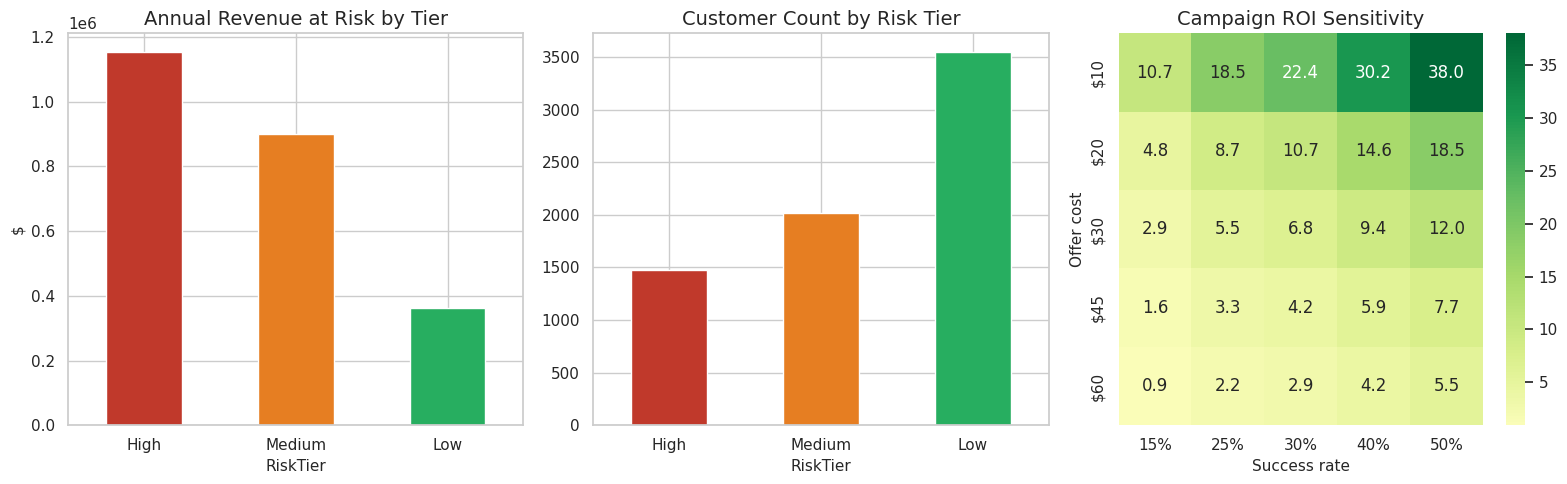

In [30]:
#cell 29
tier_summary = (
    scored.groupby("RiskTier")
    .agg(
        Customers=("ChurnProb", "size"),
        AvgProb=("ChurnProb", "mean"),
        AnnualRevenueAtRisk=("RevenueAtRisk", "sum"),
        AvgMonthlyCharges=("MonthlyCharges", "mean"),
        AvgCLV=("CLV", "mean"),
    )
    .reindex(["High", "Medium", "Low"])
)

print("=" * 60)
print("PORTFOLIO RISK SUMMARY")
print("=" * 60)
display(tier_summary.round(2))

# Campaign economics — High tier focus
OFFER_COST = 25.0
SUCCESS_RATE = 0.30

high = scored[scored["RiskTier"] == "High"]
targeted_n = len(high)
campaign_cost = targeted_n * OFFER_COST
expected_saved = (high["RevenueAtRisk"] * SUCCESS_RATE).sum()
net = expected_saved - campaign_cost

print(f"\nAssumed offer cost           : ${OFFER_COST:.0f} per customer")
print(f"Assumed retention success    : {SUCCESS_RATE*100:.0f}%")
print(f"High-risk customers targeted : {targeted_n}")
print(f"Campaign cost                : ${campaign_cost:,.0f}")
print(f"Expected annual revenue saved: ${expected_saved:,.0f}")
print(f"Net benefit                  : ${net:,.0f}")
print(f"ROI                          : {(net / campaign_cost * 100) if campaign_cost else 0:,.0f}%")

# ROI sensitivity grid
costs = [10, 20, 30, 45, 60]
rates = [0.15, 0.25, 0.30, 0.40, 0.50]
grid = []
for c in costs:
    row = []
    for r in rates:
        sav = (high["RevenueAtRisk"] * r).sum()
        n = sav - targeted_n * c
        row.append(n / (targeted_n * c) if targeted_n * c else 0)
    grid.append(row)
roi_df = pd.DataFrame(grid, index=[f"${c}" for c in costs], columns=[f"{int(r*100)}%" for r in rates])
print("\nROI sensitivity (rows=offer cost, cols=success rate):")
display(roi_df.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
tier_summary["AnnualRevenueAtRisk"].plot(
    kind="bar", ax=axes[0], color=["#c0392b", "#e67e22", "#27ae60"])
axes[0].set_title("Annual Revenue at Risk by Tier")
axes[0].set_ylabel("$")
axes[0].tick_params(axis="x", rotation=0)

scored["RiskTier"].value_counts().reindex(["High", "Medium", "Low"]).plot(
    kind="bar", ax=axes[1], color=["#c0392b", "#e67e22", "#27ae60"])
axes[1].set_title("Customer Count by Risk Tier")
axes[1].tick_params(axis="x", rotation=0)

sns.heatmap(roi_df, annot=True, fmt=".1f", cmap="RdYlGn", center=0, ax=axes[2])
axes[2].set_title("Campaign ROI Sensitivity")
axes[2].set_ylabel("Offer cost")
axes[2].set_xlabel("Success rate")
plt.tight_layout()
plt.show()


---
## 12. Persistence — Save Artifacts


In [31]:
#cell 30
# Save model, scaler, feature names, scored population, optimal threshold
model.save(ARTIFACTS_DIR / "churn_dnn.keras")
joblib.dump(scaler, ARTIFACTS_DIR / "scaler.joblib")
joblib.dump(feature_names, ARTIFACTS_DIR / "feature_names.joblib")
joblib.dump({"best_threshold": BEST_THRESHOLD, "risk_high": RISK_HIGH_THRESHOLD,
             "risk_medium": RISK_MEDIUM_THRESHOLD}, ARTIFACTS_DIR / "thresholds.joblib")

scored_out = scored[[id_col, "tenure", "MonthlyCharges", "TotalCharges", "Contract",
                     "InternetService", "ChurnProb", "RiskTier", "RevenueAtRisk", "CLV"]].copy()
scored_out.to_csv(ARTIFACTS_DIR / "scored_population.csv", index=False)

# Quick reload sanity check
reloaded = keras.models.load_model(ARTIFACTS_DIR / "churn_dnn.keras")
scaler2 = joblib.load(ARTIFACTS_DIR / "scaler.joblib")
pred_check = reloaded.predict(X_valid_s[:5], verbose=0).ravel()
print("Reload check — first 5 valid probs:", np.round(pred_check, 4))
print(f"Artifacts written to {ARTIFACTS_DIR.resolve()}:")
for p in sorted(ARTIFACTS_DIR.iterdir()):
    print(f"  {p.name:30s}  {p.stat().st_size/1024:,.1f} KB")


Reload check — first 5 valid probs: [0.0514 0.7957 0.118  0.4704 0.0198]
Artifacts written to /kaggle/working/artifacts_eais:
  best_churn_dnn.keras            235.1 KB
  churn_dnn.keras                 235.1 KB
  feature_names.joblib            0.8 KB
  scaler.joblib                   1.4 KB
  scored_population.csv           616.7 KB
  thresholds.joblib               0.1 KB
